# Parte E — Pérdida esperada E[L] por crédito y por banda de puntaje

Capa delgada sobre `src/` (núcleo §5.8): el notebook no calcula nada por su cuenta, solo llama funciones del
repositorio y muestra sus resultados. **Se edita este `.py`; el `.ipynb` lo genera `python run.py notebooks`.**

Para cada crédito de test, **E[L] = PD · LGD · EAD** (Parte E §3.2; enunciado, Parte 2, punto 5):

- **PD**: la probabilidad de incumplimiento que predice la Parte B (`results/data/pd/pred_test.parquet`, columna
  `pred_<pd.modelo>`).
- **LGD**: la pérdida dado el incumplimiento que predice la Parte D para **todo** el test, también para los créditos
  que no incumplieron (`results/data/lgd/pred_pd_test.parquet`, columna `pred_<lgd.modelo>`).
- **EAD**: el monto desembolsado en la originación (`funded_amnt`). Es **conservadora**: supone que el incumplimiento
  ocurre antes de amortizar nada.

Las bandas son cuantiles del puntaje de la scorecard de la Parte C (score = offset − factor · logit(PD); banda 1 =
menor puntaje, más riesgo). El contraste con lo observado se hace **solo con los créditos resueltos** (castigados y
pagados); los que siguen en mora van aparte con una pérdida provisional.

La corrida escribe en una **carpeta temporal**: el notebook no escribe en `data/`, `models/`, `results/` ni `blog/`
(`results/data/el/` lo consumen el blog y la app). Para la modificación en vivo, cambia `SET` (mismas claves que
`--set`) y corre todo. Ejemplos:

- otra escala de la scorecard: `SET = {"scorecard.pdo": 40}` (cambia los rangos de puntaje de cada banda, no qué
  créditos caen en cada una)
- la LGD de la regresión lineal de la Parte D: `SET = {"lgd.modelo": "lineal"}`
- menos bandas: `SET = {"bandas.n": 5}`

Los resultados versionados son otro comando: `python run.py el --config configs/el/base.yaml`.

In [1]:
CONFIG = "configs/el/base.yaml"
SET = {}

In [2]:
import tempfile
import time
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from src.common.notebooks import config_notebook

pd.set_option("display.width", 160)

# La salida va siempre a una carpeta temporal (aunque se cambie en SET); se imprime un marcador en vez de su ruta local
carpeta = Path(tempfile.mkdtemp(prefix="el_"))
MARCADOR_SALIDA = "<carpeta temporal>"
cfg = config_notebook(CONFIG, {**SET, "salida": MARCADOR_SALIDA})
cfg["salida"] = str(carpeta)

Configuración final resuelta:
scorecard:
  base: 600
  odds_base: 50
  pdo: 20
base_seed: 0
datos:
  loans: data/processed/loans_pd.parquet
  montos: data/processed/montos.parquet
pd:
  predicciones: results/data/pd/pred_test.parquet
  modelo: logistica
lgd:
  predicciones: results/data/lgd/pred_pd_test.parquet
  modelo: mlp
bandas:
  n: 10
salida: <carpeta temporal>


## 1. Corrida de la E[L] con esta configuración (carpeta temporal)

`correr_el` lee la PD de B, la LGD de D y los montos de A, calcula la E[L] de cada crédito, su puntaje y su banda, y
escribe `el_test.parquet` y `summary.json` en `salida`, que aquí es **siempre** la carpeta temporal (el marcador de la
config impresa arriba), aunque se cambie en `SET`.

In [3]:
from src.el.experimento import correr_el, texto_resumen

inicio = time.perf_counter()
resumen = correr_el(cfg)
print(f"Tiempo de la corrida: {time.perf_counter() - inicio:.1f} s")
scorecard = resumen["scorecard"]
print(f"PD: {resumen['modelo_pd']} · LGD: {resumen['modelo_lgd']} · EAD: {resumen['ead']}")
print(f"Scorecard: base {scorecard['base']:g}, odds {scorecard['odds_base']:g}:1, PDO {scorecard['pdo']:g} "
      f"(factor {scorecard['factor']:.4f}, offset {scorecard['offset']:.4f})")
print(f"Bandas: {resumen['bandas']} · pedidas {resumen['n_bandas_pedidas']}, obtenidas {resumen['n_bandas_obtenidas']}")

Tiempo de la corrida: 0.9 s
PD: logistica · LGD: mlp · EAD: funded_amnt (originación)
Scorecard: base 600, odds 50:1, PDO 20 (factor 28.8539, offset 487.1229)
Bandas: cuantiles del puntaje de la scorecard en 10 bandas; banda 1 = menor puntaje (más riesgo) · pedidas 10, obtenidas 10


In [4]:
print(texto_resumen(resumen))
print("Fracción del monto que seguía pendiente al castigo (media de los castigados): "
      f"{resumen['fraccion_principal_pendiente_media_castigados']:.3f}")

Todo el test: 74,154 créditos · EAD 1,061,569,725 USD · E[L] 197,033,511 USD
Contraste con los resueltos (n = 68,694): E[L] 178,156,880 USD · pérdida realizada 168,195,586 USD · razón 1.059
En mora, cobranza abierta (n = 5,460): E[L] 18,876,632 USD · pérdida provisional (LGD = 1 sobre el pendiente) 61,334,969 USD
Anomalía: 1,284 pagados con 1,670,029 USD de principal no registrado (no se suma a la pérdida)
Fracción del monto que seguía pendiente al castigo (media de los castigados): 0.839


## 2. Totales y por banda de puntaje (del resumen de esta corrida)

Montos en USD; tasa de malos, PD y LGD como fracciones. Lo que no aplica a una fila (la pérdida realizada de los
créditos en mora, la provisional de los resueltos) aparece como NaN.

In [5]:
from src.el.tablas import tabla_bandas, tabla_totales

tabla_totales(resumen).round(3)

,n,E[L] (USD),Pérdida realizada (USD),E[L] / realizada,Pérdida provisional (USD),Tasa de malos,PD media,LGD media
Todo el test,74154,1.970335e+08,NaN,NaN,NaN,0.262,0.187,0.917
Resueltos (contraste),68694,1.781569e+08,1.681956e+08,1.059,NaN,0.204,0.183,0.917
En mora (cobranza abierta),5460,1.887663e+07,NaN,NaN,61334969.06,1.000,0.230,0.917


In [6]:
tabla_bandas(resumen).round(3)

,Puntaje mín.,Puntaje máx.,n,E[L] (USD),n resueltos,E[L] resueltos (USD),Pérdida realizada resueltos (USD),E[L] / realizada (resueltos),n en mora,Pérdida provisional en mora (USD),Tasa de malos,PD media,LGD media
Banda,,,,,,,,,,,,,
1,457.573,505.328,7416,5.176479e+07,6464,4.503097e+07,3.971790e+07,1.134,952,14566488.40,0.476,0.416,0.919
2,505.329,515.088,7415,3.888120e+07,6613,3.461730e+07,3.237362e+07,1.069,802,12163940.53,0.389,0.309,0.917
3,515.089,523.644,7415,2.717823e+07,6712,2.461259e+07,2.272662e+07,1.083,703,8666643.03,0.336,0.246,0.918
4,523.647,530.462,7416,1.887458e+07,6739,1.713461e+07,1.648094e+07,1.040,677,6565053.65,0.309,0.200,0.919
5,530.462,535.911,7415,1.494924e+07,6846,1.375647e+07,1.484370e+07,0.927,569,5078761.31,0.276,0.168,0.918
6,535.911,540.767,7415,1.231400e+07,6925,1.152065e+07,1.226828e+07,0.939,490,3746227.35,0.240,0.145,0.918
7,540.769,545.690,7416,1.089504e+07,6987,1.023710e+07,1.017641e+07,1.006,429,3683873.37,0.202,0.125,0.917
8,545.690,551.073,7415,9.264716e+06,7043,8.780908e+06,8.755140e+06,1.003,372,3103344.23,0.172,0.107,0.916
9,551.074,558.283,7415,7.673372e+06,7134,7.367322e+06,6.635934e+06,1.110,281,2352596.40,0.134,0.089,0.915


## 3. Figuras (las del blog, dibujadas con esta corrida en la carpeta temporal)

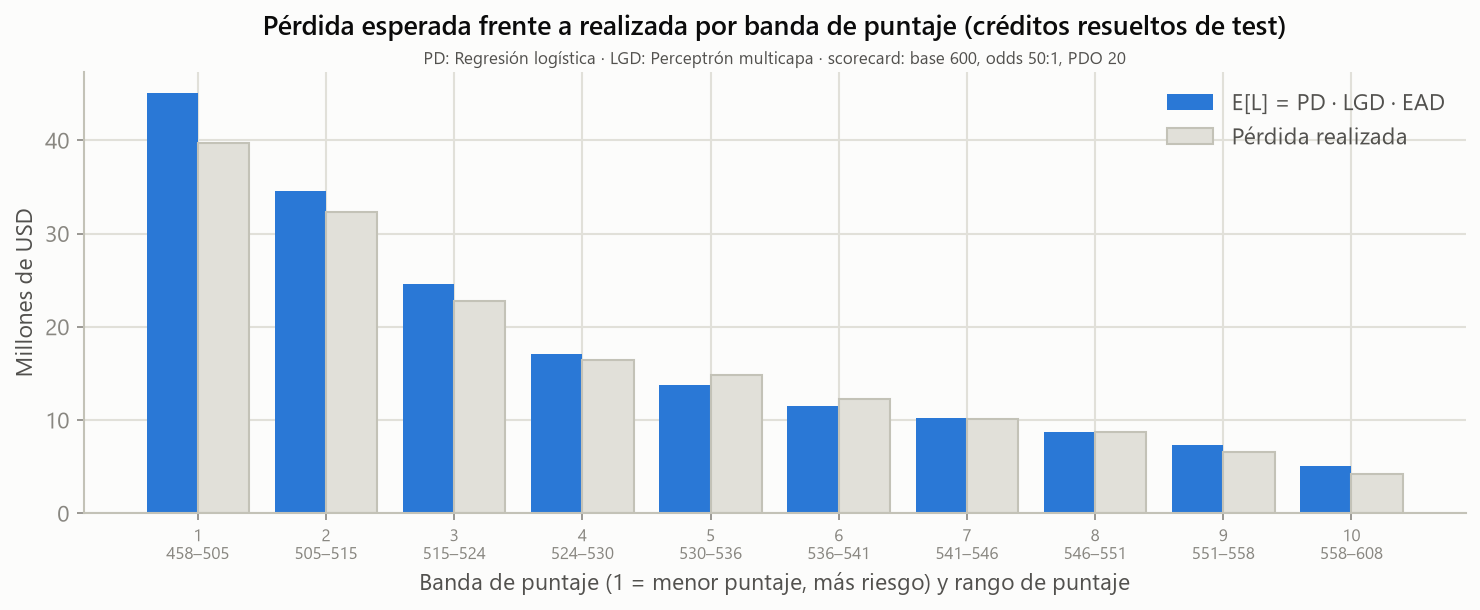

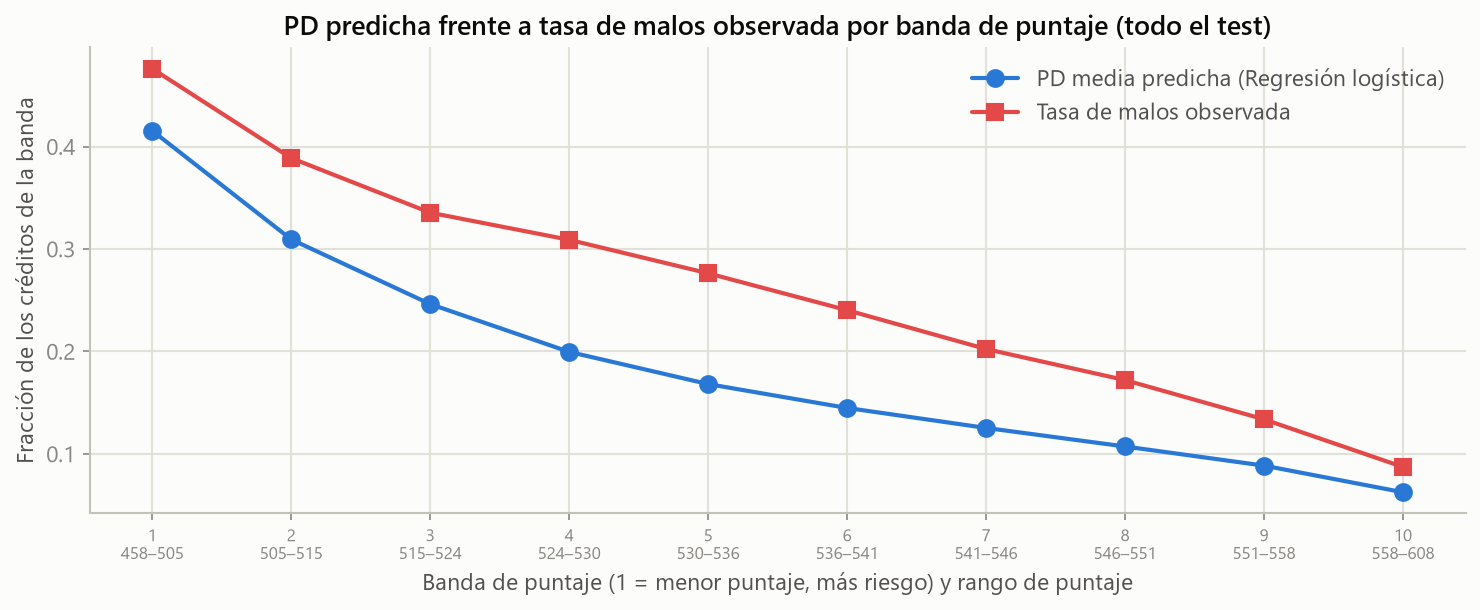

In [7]:
from src.viz.figs_el import generar

for ruta in generar(destino=carpeta / "figuras", resumen=resumen):
    display(Image(filename=str(ruta)))

## 4. Por crédito (`el_test.parquet` de esta corrida)

Unas filas de cada estado. La **pérdida realizada** (`perdida_observada`) solo existe en los créditos resueltos: en
los castigados es el principal pendiente menos las recuperaciones netas, y en los pagados es 0; en los que siguen
**en mora** es NaN, porque la cobranza no terminó. Para ellos `perdida_provisional` aplica la misma cuenta sin
recuperaciones, es decir, **supone LGD = 1** sobre el principal pendiente: no es una pérdida observada. Por eso el
contraste E[L] frente a lo realizado se hace solo con los resueltos.

In [8]:
FILAS_POR_ESTADO = 3  # solo para mostrar
COLUMNAS = ["id", "target", "estado", "pd", "score", "banda", "lgd", "ead", "el", "perdida_observada",
            "perdida_provisional"]

el_test = pd.read_parquet(carpeta / "el_test.parquet")
el_test.groupby("estado").head(FILAS_POR_ESTADO)[COLUMNAS].round(3)

,id,target,estado,pd,score,banda,lgd,ead,el,perdida_observada,perdida_provisional
0,37822187,0,pagado,0.101,550.115,8,0.916,9600.0,890.292,0.00,NaN
1,37662224,1,castigado,0.209,525.525,4,0.922,7650.0,1473.460,6945.62,NaN
2,37642222,0,pagado,0.093,552.761,9,0.922,5250.0,451.455,0.00,NaN
3,37741884,0,pagado,0.087,555.079,9,0.919,2500.0,199.150,0.00,NaN
4,37800722,1,en_mora,0.122,544.178,7,0.916,12975.0,1444.494,NaN,10346.86
7,37822030,1,en_mora,0.248,519.059,3,0.914,18450.0,4192.232,NaN,12981.68
13,37711991,1,castigado,0.152,536.819,6,0.921,14000.0,1955.409,11664.23,NaN
15,37791995,1,en_mora,0.168,533.227,5,0.930,4500.0,704.110,NaN,3444.33
29,37671924,1,castigado,0.157,535.528,5,0.903,16000.0,2274.306,14130.82,NaN


## 5. Qué parte de la razón pone cada factor (blog, 9.5)
La razón E[L] / realizada de los resueltos es el producto de un factor PD, uno LGD y uno EAD
(`src/el/tablas.py::descomposicion_razon`); cada factor vale 1 si su pieza es perfecta.

In [9]:
from src.el.tablas import descomposicion_razon

descomposicion_razon(el_test).round(3)

,E[L] / realizada,Factor PD,Factor LGD,Factor EAD
Banda,,,,
1,1.134,1.051,0.978,1.103
2,1.069,0.983,0.970,1.121
3,1.083,0.959,0.973,1.159
4,1.040,0.874,0.969,1.228
5,0.927,0.770,0.968,1.244
6,0.939,0.775,0.966,1.254
7,1.006,0.829,0.967,1.255
8,1.003,0.818,0.962,1.274
9,1.110,0.903,0.967,1.272


## 6. Cómo se lee

- **Razón E[L] / realizada (resueltos):** mayor que 1, la E[L] sobreestima la pérdida que de verdad ocurrió; menor
  que 1, la subestima. Se lee en total (sección 1) y por banda (tabla y primera figura).
- **Orden por banda:** si la PD ordena bien el riesgo, la E[L] y la pérdida realizada se concentran en las bandas de
  menor puntaje y las barras de las dos series bajan juntas al subir de banda.
- **Calibración de la PD:** la segunda figura compara la PD media predicha con la tasa de malos observada en cada
  banda; la distancia entre las dos curvas es el error de nivel de la PD, que se traslada tal cual a la E[L].
- **La EAD de originación es conservadora:** la E[L] multiplica por todo `funded_amnt`, mientras que la pérdida
  realizada parte del principal que seguía pendiente (la fracción pendiente media de los castigados está impresa en
  la sección 1). Por eso una razón cercana a 1 no prueba que la PD y la LGD estén bien por separado: una EAD alta
  puede compensar una PD o una LGD bajas. Hay que leer la razón junto con la segunda figura.
- **Créditos en mora:** su pérdida provisional no entra en el contraste; supone LGD = 1 y no es una pérdida observada.